# Phase 7 — Why the model ranks what it ranks, and what it is worth

All numbers use the **frozen Phase 6 gradient-boosting model** (`outputs/models/dev_hgb.joblib`, trained on dev
2022–2024, scored once on test 2025-01 → 2026-08). The deployment/demo model refit on all labelled data in Step H
(`deploy_hgb.joblib`) is **not used for any number here**.

Sections 1–2 explain the model (SHAP). Sections 3–4 turn test results into patches, hours and money. **Every
assumption is in the next cell — change it and re-run the notebook.** Analyses designed after the test results
(ransomware, budget policy, retraining) are descriptive and marked *post-test*.

In [1]:
# ================= ASSUMPTIONS (edit me) =================
HOURS_PER_EMERGENCY_PATCH = 6.0     # analyst/engineer hours per out-of-cycle patch: triage, test, change approval, deploy, verify
COST_PER_HOUR_USD = 100.0           # fully loaded cost of one analyst/engineer hour
SHARE_OF_FEED = 1.0                 # share of all NVD CVEs that affect YOUR estate (1.0 = the whole feed, as in this study).
                                    # Patches scale with it; we assume exploited CVEs are spread the same way.
K_MAIN = 110                        # fixed monthly capacity (pre-registered, from the 2022-24 CVSS>=9 rule)
BUDGET_SHARE = 110 / (93_842 / 36)  # volume-scaled policy: same share of each month as K=110 was of an average dev month (4.22%)
# =========================================================

In [2]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl"))
warnings.filterwarnings("ignore")
import json, textwrap
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import shap
from metrics import recall_at_k, recall_at_budget, rule_at_own_capacity
from description_leak import PHRASES, phrase_flags

FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
BLUE, ORANGE, AQUA, VIOLET, RED, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#d64545", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

meta = json.loads((ROOT / "outputs" / "models" / "dev_models.json").read_text())
dep = json.loads((ROOT / "outputs" / "models" / "deploy_models.json").read_text())
print("model explained here: frozen Phase 6 dev_hgb.joblib, sha256", meta["sha256"]["hgb"][:16])
print(f"(Step H deployment model, NOT used here: {dep['n']:,} CVEs / {dep['positives']} positives, sha256 {dep['sha256']['hgb'][:16]})")

sh = pd.read_parquet(ROOT / "data" / "shap_test.parquet")
FEATS = [c[6:] for c in sh.columns if c.startswith("shap__")]
NAME = {"vendor_key": "vendor (or CNA)", "cna": "CNA (who published)", "cwe": "CWE (CNA)", "n_cwes": "number of CWEs",
        "cvss_cna_score": "CVSS score (CNA)", "has_cna_cvss": "has CNA CVSS", "phrase_day0": "exploitation phrase (day 0)",
        "desc_len": "description length", "vendor_kev_log_all": "vendor KEV entries (all time)",
        "vendor_kev_log_365": "vendor KEV entries (last 365 d)", "vendor_kev_days_since": "days since vendor's last KEV entry",
        "vendor_kev_any": "vendor has any KEV entry", "product_kev_log_all": "product KEV entries (all time)",
        **{f"cvss_{p}": f"CVSS {p}" for p in ["AV", "AC", "PR", "UI", "S", "C", "I", "A", "AT"]}}
GROUP = {**{f: "KEV history (vendor/product)" for f in FEATS if "kev" in f},
         **{f: "CVSS (CNA)" for f in FEATS if f.startswith("cvss") or f == "has_cna_cvss"},
         "vendor_key": "who: vendor / CNA / CWE", "cna": "who: vendor / CNA / CWE", "cwe": "who: vendor / CNA / CWE", "n_cwes": "who: vendor / CNA / CWE",
         "phrase_day0": "text: phrase + length", "desc_len": "text: phrase + length"}
SV = sh[[f"shap__{f}" for f in FEATS]].to_numpy()
rand = sh["in_random"].to_numpy()
print(f"SHAP rows: {len(sh):,} (random {rand.sum():,}, exploited {sh['in_pos'].sum()}, flagged non-exploited {sh['in_flagged'].sum()}); "
      "permutation SHAP in log-odds units, additivity checked in src/phase7_explain.py")

model explained here: frozen Phase 6 dev_hgb.joblib, sha256 d8773945ca9512db
(Step H deployment model, NOT used here: 196,403 CVEs / 613 positives, sha256 627441c1e8435f73)
SHAP rows: 2,584 (random 2,000, exploited 294, flagged non-exploited 300); permutation SHAP in log-odds units, additivity checked in src/phase7_explain.py


## 1. What drives the score: global SHAP importance
SHAP splits each CVE's score (log-odds) into one contribution per input feature, relative to an average dev CVE.
Mean |SHAP| over 2,000 random test CVEs = how much a feature moves scores in general. *(Method note: the standard
tree explainer cannot handle the model's categorical CVSS splits — its values did not add up — so we use permutation
SHAP on the 22 raw inputs; values add up exactly to the model output.)*

,feature,group,mean |SHAP| random CVEs,mean |SHAP| exploited CVEs
0,CNA (who published),who: vendor / CNA / CWE,0.787,0.896
1,vendor KEV entries (all time),KEV history (vendor/product),0.645,1.135
2,CVSS score (CNA),CVSS (CNA),0.405,0.660
3,description length,text: phrase + length,0.355,0.357
4,CVSS PR,CVSS (CNA),0.353,0.370
5,CWE (CNA),who: vendor / CNA / CWE,0.305,0.268
6,vendor (or CNA),who: vendor / CNA / CWE,0.210,0.131
7,days since vendor's last KEV entry,KEV history (vendor/product),0.197,0.251
8,CVSS UI,CVSS (CNA),0.147,0.137
9,CVSS C,CVSS (CNA),0.133,0.085


,mean |SHAP| (sum over group)
who: vendor / CNA / CWE,1.403
CVSS (CNA),1.393
KEV history (vendor/product),0.909
text: phrase + length,0.355


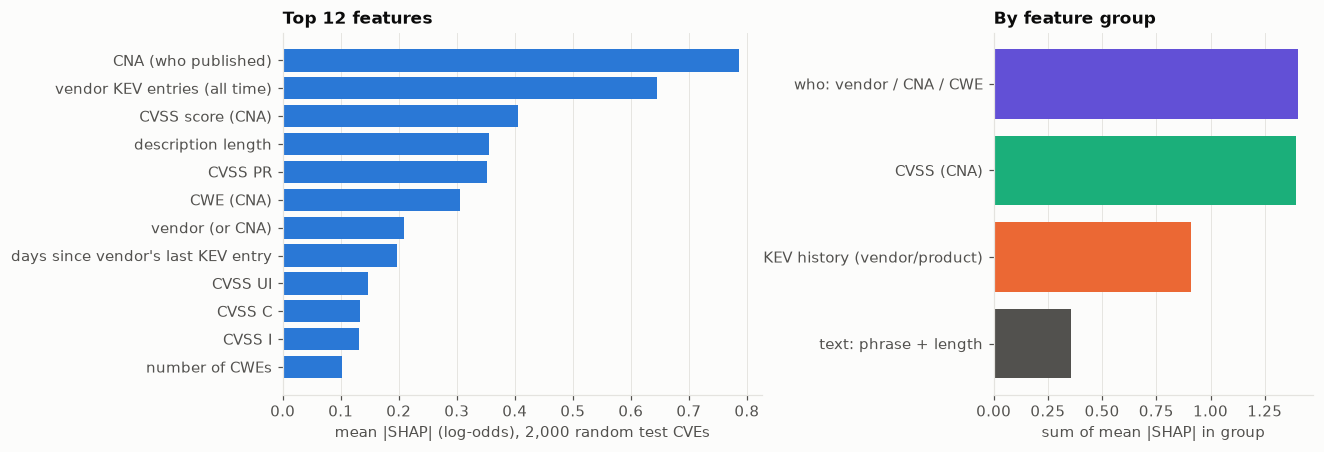

In [3]:
imp = pd.Series(np.abs(SV[rand]).mean(0), index=FEATS).sort_values(ascending=False)
imp_pos = pd.Series(np.abs(SV[sh["in_pos"]]).mean(0), index=FEATS)
gimp = imp.groupby(GROUP).sum().sort_values(ascending=False)
tbl = pd.DataFrame({"feature": [NAME[f] for f in imp.index], "group": [GROUP[f] for f in imp.index],
                    "mean |SHAP| random CVEs": imp.values, "mean |SHAP| exploited CVEs": imp_pos[imp.index].values}).round(3)
display(tbl.head(12)); tbl.to_csv(TAB / "07_shap_importance.csv", index=False)
display(gimp.round(3).to_frame("mean |SHAP| (sum over group)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
top = imp.head(12)[::-1]
axes[0].barh([NAME[f] for f in top.index], top.values, color=BLUE)
axes[0].set_xlabel("mean |SHAP| (log-odds), 2,000 random test CVEs"); axes[0].set_title("Top 12 features", loc="left"); axes[0].grid(axis="y", visible=False)
g = gimp[::-1]
axes[1].barh(g.index, g.values, color=[ORANGE if "KEV" in i else AQUA if "CVSS" in i else VIOLET if "who" in i else INK2 for i in g.index])
axes[1].set_xlabel("sum of mean |SHAP| in group"); axes[1].set_title("By feature group", loc="left"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "07_01_shap_importance")

**Takeaway**: **Who published the CVE matters most, then the vendor's KEV history, then CVSS.** Mean |SHAP| on 2,000 random test CVEs is 0.79 log-odds for **CNA**, 0.65 for **vendor KEV entries (all time)**, 0.41 for **CNA CVSS score**, 0.36 for description length and 0.35 for CVSS 'privileges required'. For **exploited** CVEs, vendor KEV history is the biggest mover (1.14), ahead of CNA (0.90) and CVSS score (0.66). By group: who (vendor/CNA/CWE) 1.40, CVSS 1.39, KEV history 0.91, text-derived 0.36. The day-0 exploitation phrase is ~0 on random CVEs because almost none have one. It is decisive for the few that do, which is the Apple pattern from Phase 3. 'vendor has any KEV entry' and 'has CNA CVSS' add nothing beyond the other features.

## 2. Beeswarm: direction of each effect
Each dot is one CVE (2,000 random test CVEs). Right = pushes towards "exploited". Colour = feature value (red high,
blue low; grey for categories such as vendor or CVSS letters, which have no natural order).

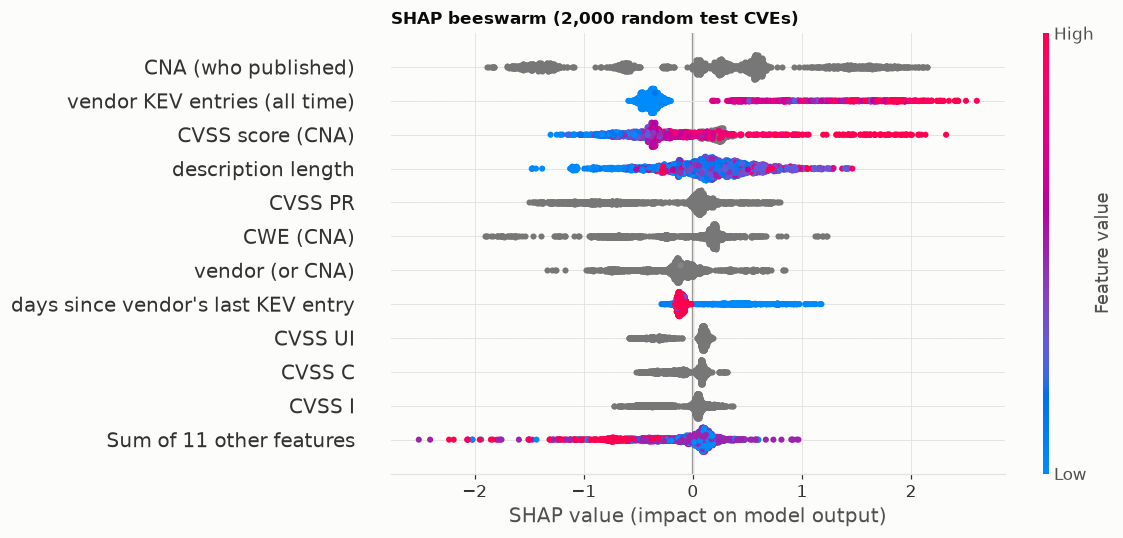

In [4]:
num = {f: pd.to_numeric(sh[f"x__{f}"], errors="coerce") for f in FEATS}
data = np.column_stack([num[f].to_numpy(float) if pd.api.types.is_numeric_dtype(num[f]) and num[f].notna().any() else np.full(len(sh), np.nan) for f in FEATS])
expl = shap.Explanation(values=SV[rand], base_values=sh.loc[rand, "base_value"].to_numpy(), data=data[rand], feature_names=[NAME[f] for f in FEATS])
plt.figure()
shap.plots.beeswarm(expl, max_display=12, show=False, plot_size=(9, 5.2))
plt.title("SHAP beeswarm (2,000 random test CVEs)", loc="left", fontweight="bold")
save(plt.gcf(), "07_02_shap_beeswarm")

**Takeaway**: **Many earlier KEV entries for the vendor (red) push scores up by up to +2.5 log-odds; none (blue) pull them down by about −0.4.** High CNA CVSS pushes up and low CVSS pushes down, but the spread is smaller than for KEV history. **A recent KEV entry for the vendor (few days since, blue) pushes up by up to +1.2.** CNA and CWE spread widely in both directions: some publishers raise scores (VulnCheck +1.6 on average; Google Chrome, Oracle, Microsoft, MITRE about +0.6), while the WordPress-plugin CNAs lower them (Wordfence −1.6, WPScan −1.5, Patchstack −1.4). Longer descriptions tend to push up mildly. The model mostly reads **who is affected and whether attackers already target that vendor**, then how severe the bug is.

## 3. Three worked examples from test
* **caught**: the highest-scoring exploited CVE in a monthly top 110 *without* a day-0 exploitation phrase;
* **missed**: the closest miss among exploited **Microsoft** CVEs of 2026 (links to the drift finding);
* **false alarm**: the highest-scoring CVE that was *not* exploited within 90 days.

Bars = the 8 largest SHAP contributions (log-odds); the score starts at the average dev CVE (base value).

--- CAUGHT EXPLOITED CVE: CVE-2026-24858 | published 2026-01-27 | vendor Fortinet / FortiWeb | CNA CVSS 9.8 | CWE CWE-288
    exploited within 90 d: True (KEV after 0 days; ransomware-linked: False) | model score 0.983, top 0.00% of its month, in top 110: True
    base value -2.55 + sum of SHAP +6.60 = log-odds +4.06
    description (day 0): An Authentication Bypass Using an Alternate Path or Channel vulnerability [CWE-288] vulnerability in Fortinet FortiAnalyzer 7.6.0 through 7.6.5, FortiAnalyzer 7.4.0 through 7.4.9, FortiAnalyzer 7.2.0 through 7.2.11, FortiAnalyzer 7.0.0 through 7.0.15, FortiManager 7.6.0 through 7.6.5, [...]

--- MISSED EXPLOITED CVE: CVE-2026-56155 | published 2026-07-14 | vendor Microsoft / Windows 10 Version 1607 | CNA CVSS 7.8 | CWE CWE-1220
    exploited within 90 d: True (KEV after 0 days; ransomware-linked: False) | model score 0.820, top 6.42% of its month, in top 110: False
    base value -2.55 + sum of SHAP +4.06 = log-odds +1.51
    description (day 0): I

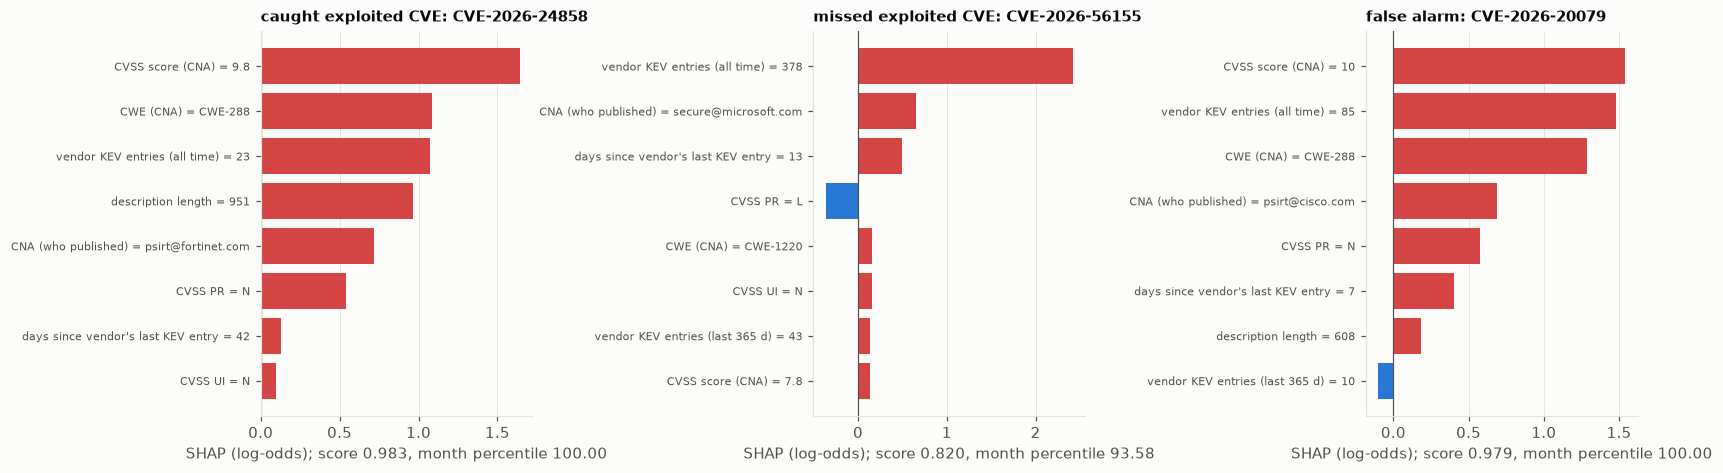

In [5]:
exs = pd.read_csv(TAB / "07_examples.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (_, e) in zip(axes, exs.iterrows()):
    r = sh[sh["cve_id"] == e["cve_id"]].iloc[0]
    contrib = pd.Series([r[f"shap__{f}"] for f in FEATS], index=FEATS)
    topc = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:8])[::-1]
    labels = []
    for f in topc.index:
        v = r[f"x__{f}"]
        if f.endswith("_log_all") or f.endswith("_log_365"):
            v = f"{np.expm1(float(v)):.0f}"          # stored as log(1 + count) -> show the count
        else:
            v = f"{float(v):.4g}" if isinstance(v, (int, float, np.floating)) and not pd.isna(v) else str(v)[:22]
        labels.append(f"{NAME[f]} = {v}")
    ax.barh(labels, topc.values, color=[RED if v > 0 else BLUE for v in topc.values])
    ax.axvline(0, color=INK2, lw=0.8); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7.5)
    ax.set_title(f"{e['example']}: {e['cve_id']}", loc="left", fontsize=9.5)
    ax.set_xlabel(f"SHAP (log-odds); score {e['s_hgb']:.3f}, month percentile {100 * e['month_pct']:.2f}")
    print(f"--- {e['example'].upper()}: {e['cve_id']} | published {e['published'][:10]} | vendor {e['vendor']} / {e['product']} | CNA CVSS {e['cvss_cna_score']} | CWE {e['cwe']}")
    print(f"    exploited within 90 d: {bool(e['label'])}" + (f" (KEV after {e['days_to_kev']:.0f} days; ransomware-linked: {e['kev_ransomware']})" if e['label'] else "")
          + f" | model score {e['s_hgb']:.3f}, top {100 * (1 - e['month_pct']):.2f}% of its month, in top 110: {e['in_top110']}")
    print(f"    base value {r['base_value']:+.2f} + sum of SHAP {r['log_odds'] - r['base_value']:+.2f} = log-odds {r['log_odds']:+.2f}")
    print("    description (day 0): " + textwrap.shorten(str(e["description_day0"]), 300) + "\n")
fig.tight_layout(); save(fig, "07_03_worked_examples")

**Takeaway**: **Caught: CVE-2026-24858 (Fortinet FortiWeb/FortiAnalyzer authentication bypass, CVSS 9.8).** It ranked #1 in its month. The drivers are CVSS 9.8 (+1.6), CWE-288 authentication bypass (+1.1), Fortinet's 24 earlier KEV entries (+1.1), a long detailed description (+1.0) and the Fortinet PSIRT as publisher (+0.7). CISA listed it in KEV the same day. **Missed: CVE-2026-56155 (Microsoft AD FS privilege escalation, CVSS 7.8, local).** Microsoft's ~364 KEV entries push it up strongly (+2.4), but it is a local, authenticated privilege escalation with a 7.8 score. It landed in the top 6.4% of a ~9,000-CVE month, outside the top 110. This is the 2026 drift in one CVE: dozens of Microsoft CVEs a month get the same KEV-history push, and a fixed 110 slots can't hold them all. **False alarm: CVE-2026-20079 (Cisco FMC unauthenticated auth bypass to root, CVSS 10.0).** It looks exactly like an exploited CVE: CVSS 10 (+1.5), Cisco's ~89 KEV entries (+1.5), CWE-288 (+1.3). It *was* added to KEV, **189 days after publication**, so it counts as 'not exploited' only because of the 90-day label window. This is not typical but not rare at the top: **3% of the non-exploited CVEs in the monthly top 10** (5 of 164) and 0.8% in the top 110 (16 of 2,100) were later added to KEV, vs 0.05% of all non-exploited CVEs. Some 'false alarms' are exploits that came late.

## 4. Vendor KEV history in 2025 vs 2026 (links to the Phase 6 drift finding)
Notebook 06 (§7) found that in 2026 far more CVEs come from vendors with earlier KEV entries (2,376 a month vs
1,246 in 2025), so the model's strongest signal marks many more CVEs. Here: how much does the KEV-history group move
scores in each year, for exploited and for non-exploited CVEs?

year,2025,2026
random CVEs,900.00,1100.00
exploited CVEs,159.00,135.00
KEV group mean |SHAP| (random),0.82,0.98
KEV group share of all |SHAP| %,20.98,23.47
"KEV group mean SHAP, exploited",1.06,1.04
"KEV group mean SHAP, non-exploited (random)",0.00,0.23
% of non-exploited with KEV push > +1,18.75,26.64
% of exploited with KEV push > +1,54.09,59.26
rank of 'vendor KEV entries (365 d)',16.00,17.00


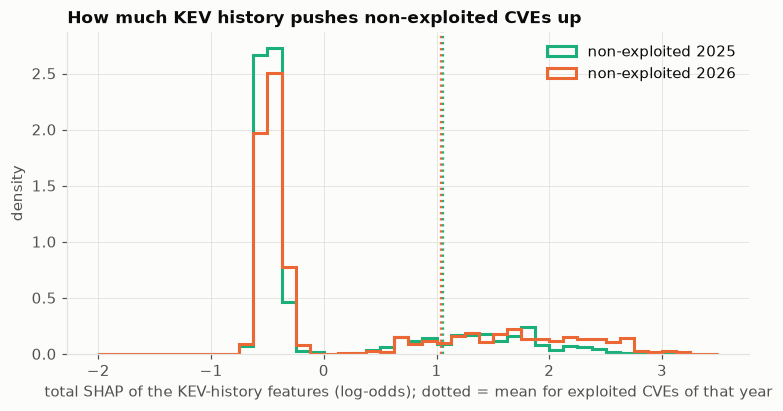

In [6]:
kev_cols = [i for i, f in enumerate(FEATS) if GROUP[f].startswith("KEV")]
sh["shap_kev_group"] = SV[:, kev_cols].sum(1)
rows = []
for y in (2025, 2026):
    r_ = sh[rand & (sh["year"] == y)]; p_ = sh[sh["in_pos"] & (sh["year"] == y)]; neg = r_[r_["label"] == 0]
    imp_y = pd.Series(np.abs(SV[(rand & (sh["year"] == y)).to_numpy()]).mean(0), index=FEATS)
    rows.append({"year": y, "random CVEs": len(r_), "exploited CVEs": len(p_),
                 "KEV group mean |SHAP| (random)": imp_y.iloc[kev_cols].sum(),
                 "KEV group share of all |SHAP| %": 100 * imp_y.iloc[kev_cols].sum() / imp_y.sum(),
                 "KEV group mean SHAP, exploited": p_["shap_kev_group"].mean(),
                 "KEV group mean SHAP, non-exploited (random)": neg["shap_kev_group"].mean(),
                 "% of non-exploited with KEV push > +1": 100 * (neg["shap_kev_group"] > 1).mean(),
                 "% of exploited with KEV push > +1": 100 * (p_["shap_kev_group"] > 1).mean(),
                 "rank of 'vendor KEV entries (365 d)'": int(imp_y.rank(ascending=False)["vendor_kev_log_365"])})
kevy = pd.DataFrame(rows).set_index("year"); display(kevy.T.round(2)); kevy.to_csv(TAB / "07_shap_kev_by_year.csv")

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(-2, 3.5, 45)
for y, c in [(2025, AQUA), (2026, ORANGE)]:
    neg = sh[rand & (sh["year"] == y) & (sh["label"] == 0)]["shap_kev_group"]
    ax.hist(neg, bins=bins, density=True, histtype="step", lw=2, color=c, label=f"non-exploited {y}")
    ax.axvline(sh[sh["in_pos"] & (sh["year"] == y)]["shap_kev_group"].mean(), color=c, ls=":", lw=1.5)
ax.set_xlabel("total SHAP of the KEV-history features (log-odds); dotted = mean for exploited CVEs of that year")
ax.set_ylabel("density"); ax.legend(frameon=False); ax.set_title("How much KEV history pushes non-exploited CVEs up", loc="left")
save(fig, "07_04_kev_shap_by_year")

**Takeaway**: **KEV history pushes more non-exploited CVEs up in 2026.** For exploited CVEs the push is unchanged (mean +1.06 in 2025, +1.04 in 2026). For non-exploited random CVEs it rose from **0.00 to +0.23** on average, and the share of non-exploited CVEs with a KEV push above +1 log-odds rose from **18.8% to 26.6%**. The group's share of all SHAP mass went from 21.0% to 23.5%. The signal didn't get weaker for exploited CVEs; it now applies to many more CVEs that aren't exploited. That is the mechanism behind the 2026 drop in notebook 06: more look-alikes compete for the same 110 slots.

## 5. Business impact
Inputs: test-period CVEs (2025-01 → 2026-08), the frozen model's scores and the day-0 rules. Patches and hours are
per month for the whole NVD feed, scaled by `SHARE_OF_FEED`. **"Extra exploited CVEs caught" are CVEs that
attackers exploited within 90 days and that would have been patched in the emergency cycle instead of the regular
one.**

In [7]:
t = pd.read_parquet(ROOT / "data" / "test_locked.parquet", columns=["cve_id", "published", "label", "cvss_cna_score", "description_day0", "kev_ransomware"])
s6 = pd.read_parquet(ROOT / "data" / "phase6_scores_test.parquet"); rl = pd.read_parquet(ROOT / "data" / "post_test_rolling_scores.parquet")
assert (s6["cve_id"].to_numpy() == t["cve_id"].to_numpy()).all() and (rl["cve_id"].to_numpy() == t["cve_id"].to_numpy()).all()
t["gb"], t["rolling"] = s6["s_hgb"].to_numpy(), rl["s_rolling"].to_numpy()
t["phrase"] = phrase_flags(t["description_day0"], PHRASES).any(axis=1); t["year"] = t["published"].dt.year
t["best_rule"] = 100 * t["phrase"] + t["cvss_cna_score"].fillna(-1); t["cvss_rank"] = t["cvss_cna_score"].fillna(-1)
n_months = t["published"].dt.to_period("M").nunique()
EXPLOITED_PER_YEAR = t["label"].sum() / n_months * 12 * SHARE_OF_FEED
print(f"exploited CVEs per year (test rate x SHARE_OF_FEED): {EXPLOITED_PER_YEAR:.0f}")

def k_to_match(df, score, target):
    lo, hi = 1, 4000
    while hi - lo > 1:
        mid = (lo + hi) // 2
        lo, hi = (lo, mid) if recall_at_k(df, df[score], mid) >= target else (mid, hi)
    return hi

# a. same capacity
rows = []
for comp, kk in [("phrase, then CVSS (CNA) ranking", K_MAIN), ("CVSS (CNA) ranking", K_MAIN)]:
    col = "best_rule" if comp.startswith("phrase") else "cvss_rank"
    rg, rc = recall_at_k(t, t["gb"], kk), recall_at_k(t, t[col], kk)
    rows.append({"comparison": f"GB vs {comp}, both at K = {kk}/month", "patches / month": kk * SHARE_OF_FEED,
                 "GB recall %": 100 * rg, "comparator recall %": 100 * rc, "extra exploited caught / year": (rg - rc) * EXPLOITED_PER_YEAR})
for rname, flag in [("CVSS>=9 (CNA) rule", t["cvss_cna_score"] >= 9), ("phrase OR CVSS>=9 (CNA) rule", t["phrase"] | (t["cvss_cna_score"] >= 9))]:
    o = rule_at_own_capacity(t, flag); rg = recall_at_k(t, t["gb"], o["patches_per_month"])
    rows.append({"comparison": f"GB vs {rname}, at the rule's own capacity", "patches / month": o["patches_per_month"] * SHARE_OF_FEED,
                 "GB recall %": 100 * rg, "comparator recall %": 100 * o["recall"], "extra exploited caught / year": (rg - o["recall"]) * EXPLOITED_PER_YEAR})
same_cap = pd.DataFrame(rows).set_index("comparison"); display(same_cap.round(1)); same_cap.to_csv(TAB / "07_same_capacity.csv")

exploited CVEs per year (test rate x SHARE_OF_FEED): 176


,patches / month,GB recall %,comparator recall %,extra exploited caught / year
comparison,,,,
"GB vs phrase, then CVSS (CNA) ranking, both at K = 110/month",110.0,33.7,25.2,14.9
"GB vs CVSS (CNA) ranking, both at K = 110/month",110.0,33.7,18.6,26.6
"GB vs CVSS>=9 (CNA) rule, at the rule's own capacity",384.9,51.7,41.2,18.6
"GB vs phrase OR CVSS>=9 (CNA) rule, at the rule's own capacity",386.6,51.7,47.3,7.8


**Takeaway**: Over the test period there are about **176 exploited CVEs a year**. At **110 patches a month**, gradient boosting catches **~59 a year**, vs ~44 for the best day-0 rule (**+15 a year**) and ~33 for CVSS ranking (**+27 a year**). At the **CVSS ≥ 9 rule's own capacity (385 a month)** it catches **+19 exploited CVEs a year** (51.7% vs 41.2%). Against 'phrase OR CVSS ≥ 9' (387 a month) the gain is **+8 a year** (51.7% vs 47.3%).

### 5b. Same recall: how many patches does the model need to match each rule?
Smallest K per month at which gradient boosting catches at least the rule's share of exploited CVEs, overall and
per year (2026 matters: the rule's own capacity grew to ~600 patches a month).

,period,rule,rule patches / month,rule recall %,GB (frozen) patches / month to match,patches saved / month,analyst hours saved / year,cost saved / year (USD),GB rolling-retrain patches / month to match
0,all test,CVSS>=9 (CNA),384.9,41.2,198.0,186.9,13456.8,1345680.0,148.0
1,all test,phrase OR CVSS>=9 (CNA),386.6,47.3,265.0,121.6,8751.6,875160.0,205.0
2,2025,CVSS>=9 (CNA),237.5,36.5,83.0,154.5,11124.0,1112400.0,106.0
3,2025,phrase OR CVSS>=9 (CNA),239.7,45.9,155.0,84.7,6096.0,609600.0,147.0
4,2026 (Jan-Aug),CVSS>=9 (CNA),606.0,46.7,569.0,37.0,2664.0,266400.0,302.0
5,2026 (Jan-Aug),phrase OR CVSS>=9 (CNA),606.9,48.9,630.0,-23.1,-1665.0,-166500.0,330.0


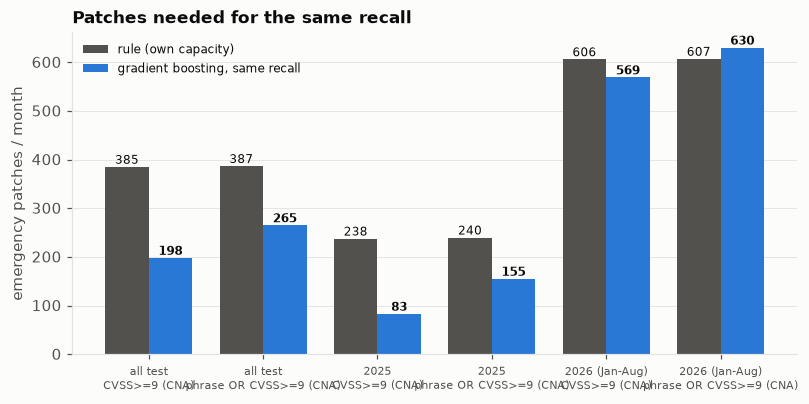

In [8]:
rows = []
for period, part in [("all test", t), ("2025", t[t["year"] == 2025]), ("2026 (Jan-Aug)", t[t["year"] == 2026])]:
    for rname, flag in [("CVSS>=9 (CNA)", part["cvss_cna_score"] >= 9), ("phrase OR CVSS>=9 (CNA)", part["phrase"] | (part["cvss_cna_score"] >= 9))]:
        o = rule_at_own_capacity(part, flag)
        kg = k_to_match(part, "gb", o["recall"]); kr = k_to_match(part, "rolling", o["recall"])
        saved = (o["patches_per_month"] - kg) * SHARE_OF_FEED
        rows.append({"period": period, "rule": rname, "rule patches / month": o["patches_per_month"] * SHARE_OF_FEED, "rule recall %": 100 * o["recall"],
                     "GB (frozen) patches / month to match": kg * SHARE_OF_FEED, "patches saved / month": saved,
                     "analyst hours saved / year": saved * 12 * HOURS_PER_EMERGENCY_PATCH,
                     "cost saved / year (USD)": saved * 12 * HOURS_PER_EMERGENCY_PATCH * COST_PER_HOUR_USD,
                     "GB rolling-retrain patches / month to match": kr * SHARE_OF_FEED})
same_rec = pd.DataFrame(rows); display(same_rec.round(1)); same_rec.to_csv(TAB / "07_same_recall.csv", index=False)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(same_rec)); w = 0.38
ax.bar(x - w/2, same_rec["rule patches / month"], w, color=INK2, label="rule (own capacity)")
ax.bar(x + w/2, same_rec["GB (frozen) patches / month to match"], w, color=BLUE, label="gradient boosting, same recall")
for xi, (a, b) in enumerate(zip(same_rec["rule patches / month"], same_rec["GB (frozen) patches / month to match"])):
    ax.annotate(f"{a:.0f}", (xi - w/2, a), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8)
    ax.annotate(f"{b:.0f}", (xi + w/2, b), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8, weight="bold")
ax.set_xticks(x, [f"{p}\n{r}" for p, r in zip(same_rec["period"], same_rec["rule"])], fontsize=7.5); ax.grid(axis="x", visible=False)
ax.set_ylabel("emergency patches / month"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Patches needed for the same recall", loc="left"); save(fig, "07_05_same_recall")

**Takeaway**: **Over the whole test period, gradient boosting matches the CVSS ≥ 9 rule's 41% recall with 198 patches a month instead of 385.** That saves **187 patches a month, ~13,500 analyst hours and ~$1.35M a year** at 6 h per patch and $100/h. Against 'phrase OR CVSS ≥ 9' it needs 265 instead of 387 (122 fewer a month, ~8,750 h, ~$0.9M). **The saving is concentrated in 2025** (83 vs 238 patches). **In 2026 the frozen model barely saves anything** (569 vs 606 against CVSS ≥ 9), **and it needs more patches than 'phrase OR CVSS ≥ 9'** (630 vs 607). **A quarterly-retrained model restores the advantage in 2026: 302 patches vs 606** (about half). The saving is real but needs a maintained model.

### 5c. Ransomware-linked CVEs (post-test, descriptive)
KEV's `knownRansomwareCampaignUse` = "Known" marks CVEs used in ransomware campaigns (a hindsight field, used only
to evaluate, never as a feature). Same monthly rankings as before; recall counted only over ransomware-linked
exploited CVEs. EPSS keeps its caveats (lookahead, possible use of KEV).

subset,all exploited,ransomware-linked exploited,"exploited, not ransomware-linked"
method,,,
CVSS (CNA) ranking,18.6 [14–23],24.6 [11–39],17.5 [13–22]
"EPSS (first score, <=7 d after pub)",29.6 [24–35],27.9 [15–42],29.9 [24–35]
EPSS (score by day 1),29.6 [24–35],27.9 [15–42],29.9 [24–35]
gradient boosting (headline),33.7 [28–39],42.2 [27–57],32.2 [26–38]
late fusion (alternative),29.3 [24–35],37.2 [24–52],28.0 [22–33]
"phrase, then CVSS (CNA)",25.2 [20–30],26.7 [13–41],24.9 [19–30]


,positives,recall@110 [95% CI],recall@385 [95% CI]
method,,,
gradient boosting (headline),43,42.2 [27–57],65.1 [51–79]
late fusion (alternative),43,37.2 [24–52],74.4 [59–86]
"phrase, then CVSS (CNA)",43,26.7 [13–41],55.7 [39–71]
CVSS (CNA) ranking,43,24.6 [11–39],53.5 [37–70]
"EPSS (first score, <=7 d after pub)",43,27.9 [15–42],51.2 [36–67]
EPSS (score by day 1),43,27.9 [15–42],51.2 [36–67]


,rule,ransomware positives,caught,recall %
0,CVSS>=9 (CNA) at own capacity (385/month),43,25,58.139535


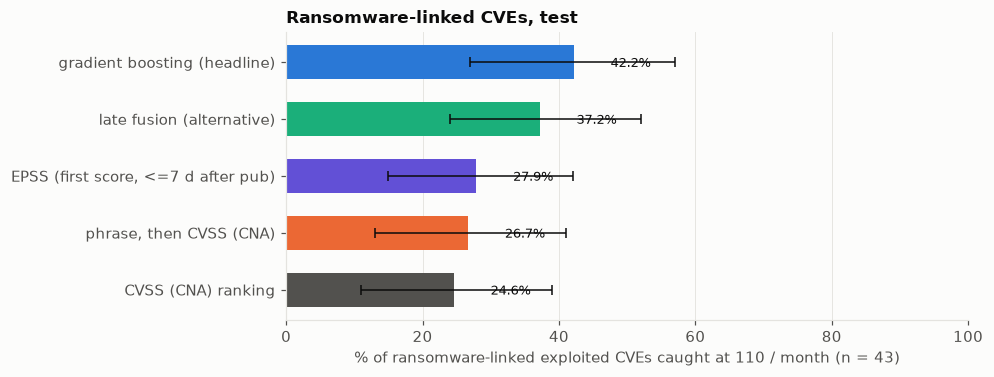

In [9]:
rw = pd.read_csv(TAB / "07_ransomware.csv")
display(rw.pivot(index="method", columns="subset", values="recall@110 [95% CI]")[["all exploited", "ransomware-linked exploited", "exploited, not ransomware-linked"]])
display(rw[rw["subset"] == "ransomware-linked exploited"].set_index("method")[["positives", "recall@110 [95% CI]", "recall@385 [95% CI]"]])
rr = pd.read_csv(TAB / "07_ransomware_rule.csv"); display(rr)
sub = rw[rw["subset"] == "ransomware-linked exploited"].set_index("method")
order = ["gradient boosting (headline)", "late fusion (alternative)", "EPSS (first score, <=7 d after pub)", "phrase, then CVSS (CNA)", "CVSS (CNA) ranking"]
fig, ax = plt.subplots(figsize=(8, 3.4))
ci = sub.loc[order, "recall@110 [95% CI]"].str.extract(r"([\d.]+) \[(\d+)–(\d+)\]").astype(float)
yy = np.arange(len(order))[::-1]
ax.barh(yy, ci[0], color=[BLUE, AQUA, VIOLET, ORANGE, INK2], height=0.6)
ax.errorbar(ci[0], yy, xerr=[ci[0] - ci[1], ci[2] - ci[0]], fmt="none", ecolor=INK, capsize=3, lw=1)
for yi, v in zip(yy, ci[0]): ax.annotate(f"{v:.1f}%", (v, yi), xytext=(24, -3), textcoords="offset points", fontsize=8.5)
ax.set_yticks(yy, order); ax.grid(axis="y", visible=False); ax.set_xlim(0, 100)
ax.set_xlabel(f"% of ransomware-linked exploited CVEs caught at 110 / month (n = {int(sub['positives'].iloc[0])})")
ax.set_title("Ransomware-linked CVEs, test", loc="left"); save(fig, "07_06_ransomware")

**Takeaway**: On the **43 ransomware-linked exploited CVEs**, gradient boosting catches **42.2% [27–57] at 110 a month**, vs **27.9%** for EPSS, **26.7%** for the best rule and **24.6%** for CVSS ranking. At 385 a month it catches 65.1% vs the CVSS ≥ 9 rule's 58.1% (25 of 43); the fusion reaches 74.4% at 385. The model does *better* on ransomware-linked CVEs than on the rest (42.2% vs 32.2%), probably because ransomware groups favour edge devices and enterprise software from vendors with long KEV histories. The CIs are wide (43 CVEs), so read this as 'at least as good on the most damaging CVEs', not as a precise gain.

### 5d. Operating policy: scale K with volume, retrain quarterly (post-test, exploratory)
Two levers from notebook 06: **(i) budget** = fixed K = 110 a month vs a fixed *share* of each month's CVEs
(`BUDGET_SHARE` = 4.22%, the share K = 110 represented in 2022–24); **(ii) model** = frozen vs retrained every quarter
(90-day label delay respected). A share-based budget uses more patches when volume grows, so it is also compared with
a **fixed K that spends the same total** (fair comparison).

,period,model,fixed K=110: recall %,volume-scaled 4.22%: recall %,"fixed K, same total patches: recall %",scaled: avg patches / month,extra hours / year vs K=110
0,2025,frozen,41.9,49.7,48.1,169.3,4271.2
1,2025,rolling quarterly retrain,37.5,49.1,50.3,169.3,4271.2
2,2026 (Jan-Aug),frozen,23.9,34.1,37.0,287.0,12744.6
3,2026 (Jan-Aug),rolling quarterly retrain,31.3,44.4,45.9,287.0,12744.6
4,all test,frozen,33.7,42.5,41.8,216.4,7660.5
5,all test,rolling quarterly retrain,34.7,46.9,48.0,216.4,7660.5


CVEs per month in test: min 3020 max 9771 -> scaled budget from 127 to 412 patches / month


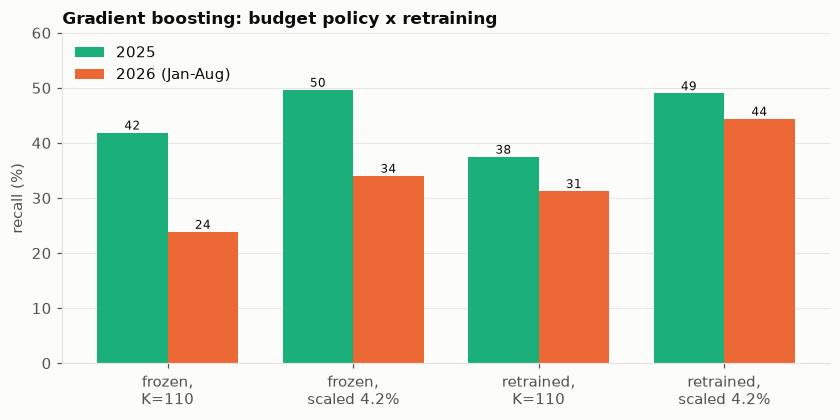

In [10]:
rows = []
for period, part in [("2025", t[t["year"] == 2025]), ("2026 (Jan-Aug)", t[t["year"] == 2026]), ("all test", t)]:
    mo = part["published"].dt.to_period("M").nunique()
    k_eq = BUDGET_SHARE * len(part) / mo
    for model in ["gb", "rolling"]:
        rows.append({"period": period, "model": "frozen" if model == "gb" else "rolling quarterly retrain",
                     "fixed K=110: recall %": 100 * recall_at_k(part, part[model], K_MAIN),
                     "volume-scaled 4.22%: recall %": 100 * recall_at_budget(part, part[model], BUDGET_SHARE),
                     "fixed K, same total patches: recall %": 100 * recall_at_k(part, part[model], k_eq),
                     "scaled: avg patches / month": k_eq * SHARE_OF_FEED,
                     "extra hours / year vs K=110": (k_eq - K_MAIN) * SHARE_OF_FEED * 12 * HOURS_PER_EMERGENCY_PATCH})
pol = pd.DataFrame(rows); display(pol.round(1)); pol.to_csv(TAB / "07_policy.csv", index=False)
mby = t.groupby(t["published"].dt.to_period("M")).size()
print("CVEs per month in test: min", mby.min(), "max", mby.max(), "-> scaled budget from", round(BUDGET_SHARE * mby.min()), "to", round(BUDGET_SHARE * mby.max()), "patches / month")

fig, ax = plt.subplots(figsize=(9, 3.9))
pv = pol[pol["period"] != "all test"]
labels = ["frozen,\nK=110", "frozen,\nscaled 4.2%", "retrained,\nK=110", "retrained,\nscaled 4.2%"]
x = np.arange(4); w = 0.38
for j, (period, c) in enumerate([("2025", AQUA), ("2026 (Jan-Aug)", ORANGE)]):
    p = pv[pv["period"] == period].set_index("model")
    v = [p.loc["frozen", "fixed K=110: recall %"], p.loc["frozen", "volume-scaled 4.22%: recall %"],
         p.loc["rolling quarterly retrain", "fixed K=110: recall %"], p.loc["rolling quarterly retrain", "volume-scaled 4.22%: recall %"]]
    ax.bar(x + (j - 0.5) * w, v, w, color=c, label=period)
    for xi, vi in zip(x, v): ax.annotate(f"{vi:.0f}", (xi + (j - 0.5) * w, vi), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8)
ax.set_xticks(x, labels); ax.grid(axis="x", visible=False); ax.set_ylabel("recall (%)"); ax.set_ylim(0, 60)
ax.legend(frameon=False); ax.set_title("Gradient boosting: budget policy x retraining", loc="left"); save(fig, "07_07_policy")

**Takeaway**: **Capacity is the bigger lever; retraining is the second.** Scaling the budget with volume (4.22% of each month, 127–412 patches a month in test, avg 216) raises the frozen model from 33.7% to **42.5%**. Scaling plus quarterly retraining reaches **46.9%**: **44.4% in 2026** (vs 23.9% at frozen K = 110) and 49.1% in 2025. A fixed K spending the same total patches does about as well (41.8% / 48.0%). So the gain comes from **keeping capacity in line with CVE volume**, not from the share rule itself. Cost: an average of +106 patches a month over 110, about **+7,700 analyst hours a year** (+12,700 at the 2026 rate). Retraining alone at K = 110 is break-even overall (+1.0) but +7.4 points in 2026.

## 6. Side-by-side: business view of all methods (test, K = 110 / month and rules at own capacity)

In [11]:
final = pd.DataFrame({
    "recall@110 %": {"gradient boosting (frozen)": 100 * recall_at_k(t, t["gb"], 110), "gradient boosting (rolling retrain, post-test)": 100 * recall_at_k(t, t["rolling"], 110),
                     "phrase, then CVSS (CNA)": 100 * recall_at_k(t, t["best_rule"], 110), "CVSS (CNA) ranking": 100 * recall_at_k(t, t["cvss_rank"], 110)},
    "exploited caught / year @110": {}})
final["exploited caught / year @110"] = final["recall@110 %"] / 100 * EXPLOITED_PER_YEAR
final["ransomware-linked recall@110 %"] = [sub.loc["gradient boosting (headline)", "recall@110"], np.nan, sub.loc["phrase, then CVSS (CNA)", "recall@110"], sub.loc["CVSS (CNA) ranking", "recall@110"]]
final["patches / month"] = 110 * SHARE_OF_FEED
final["hours / year"] = final["patches / month"] * 12 * HOURS_PER_EMERGENCY_PATCH
display(final.round(1)); final.to_csv(TAB / "07_final_business.csv")

,recall@110 %,exploited caught / year @110,ransomware-linked recall@110 %,patches / month,hours / year
gradient boosting (frozen),33.7,59.4,42.2,110.0,7920.0
"gradient boosting (rolling retrain, post-test)",34.7,61.1,NaN,110.0,7920.0
"phrase, then CVSS (CNA)",25.2,44.4,26.7,110.0,7920.0
CVSS (CNA) ranking,18.6,32.8,24.6,110.0,7920.0


## 7. Summary for the CISO

**Takeaway**: **Recommendation: replace 'patch everything with CVSS ≥ 9' with a model-ranked emergency list, retrained every quarter, with capacity reviewed against CVE volume.** On 20 months of unseen data (2025-01 → 2026-08, 294 exploited CVEs), the model caught **33.7% of exploited CVEs with 110 emergency patches a month**, vs 25.2% for the best rule a careful team could run today and 18.6% for CVSS ranking. That is **+15 to +27 more exploited CVEs patched early each year at the same workload**. At the CVSS ≥ 9 rule's own workload (385 patches a month) it catches 51.7% vs 41.2%. To match that rule's coverage it needs **198 patches a month instead of 385, about 13,500 analyst hours (~$1.35M) a year at our assumptions**. On **ransomware-linked** CVEs it catches 42% vs 25–28% for the rules and EPSS. **Against EPSS**, the industry score, the model is ahead overall (33.7% vs 29.6%, not statistically clear). **But 37% of all exploited CVEs (109 of 294) were already in CISA's KEV list when EPSS produced the score used**, and EPSS is assumed to use KEV. On CVEs not yet in KEV, the model catches **30.4% vs 14.6%** for EPSS. **Caveat: with very small capacity (≤ 50 patches a month), EPSS ranks its very top slightly better**, and EPSS needs a day longer (only 30% of CVEs have an EPSS score on publication day). **The risk is drift**: in 2026 CVE volume rose 70% and many more CVEs came from vendors already in KEV. The frozen model fell to 23.9% at a fixed 110 patches, and lost its workload advantage. **Retraining each quarter (31.3% in 2026) and sizing capacity to ~4% of each month's CVEs (44% in 2026 with retraining)** recover most of the loss. Budget about 7,700 extra hours a year at today's volumes for the larger patch list, or accept lower coverage at 110. Explanations are available for every ranked CVE: vendor's exploitation history, publisher, severity and bug type.